# 04 · Hybrid dan Perbandingan Model

Model hybrid = rata-rata ramalan SARIMAX dan Prophet dengan bobot tetap **50/50**. Bobot ditentukan sebelum melihat data uji. Rata-rata sederhana adalah pilihan standar dalam literatur kombinasi ramalan karena sulit dikalahkan bobot hasil optimasi ketika datanya sedikit.

Semua model dibandingkan dengan **baseline seasonal naive** (ramalan = nilai bulan yang sama tahun lalu). Model yang tidak bisa mengalahkan baseline ini tidak layak dipakai.

In [1]:
import sys
sys.path.insert(0, '..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.forecasting import *

quiet()
setup_plot()
pd.options.display.float_format = '{:,.2f}'.format

In [2]:
y = load_passengers()
train, test = y[:'2022'], y['2023']
sarimax = pd.read_csv('../data/processed/ramalan_sarimax.csv', index_col=0, parse_dates=True)['SARIMAX']
prophet = pd.read_csv('../data/processed/ramalan_prophet.csv', index_col=0, parse_dates=True)['Prophet']

preds = pd.DataFrame({
    'Aktual': test,
    'SARIMAX': sarimax.to_numpy(),
    'Prophet': prophet.to_numpy(),
    'Hybrid': 0.5 * sarimax.to_numpy() + 0.5 * prophet.to_numpy(),
    'Seasonal naive': seasonal_naive(train, 12),
}, index=test.index)
preds.round(0).astype(int)

,Aktual,SARIMAX,Prophet,Hybrid,Seasonal naive
date,,,,,
2023-01-31,1204527,1016153,1050862,1033507,658075
2023-02-28,1139583,1001703,889077,945390,562194
2023-03-31,1139583,1110314,1063800,1087057,746223
2023-04-30,1215575,1154766,1182627,1168697,741469
2023-05-31,1337289,1251836,1011160,1131498,1143389
2023-06-30,1337942,1284123,1089785,1186954,1043487
2023-07-31,1460633,1301873,1217457,1259665,1250044
2023-08-31,1249071,1162713,1041956,1102334,990065
2023-09-30,1278141,1184709,975768,1080238,1018177


## 1. Hasil evaluasi (data uji 2023)

In [3]:
results = metrics_table(test, preds.drop(columns='Aktual'))
results

,MAE,RMSE,MAPE (%)
SARIMAX,"82,958.24","98,233.37",6.50
Hybrid,"131,074.02","146,568.06",10.23
Prophet,"196,080.49","214,892.66",15.16
Seasonal naive,"310,083.17","342,252.64",24.94


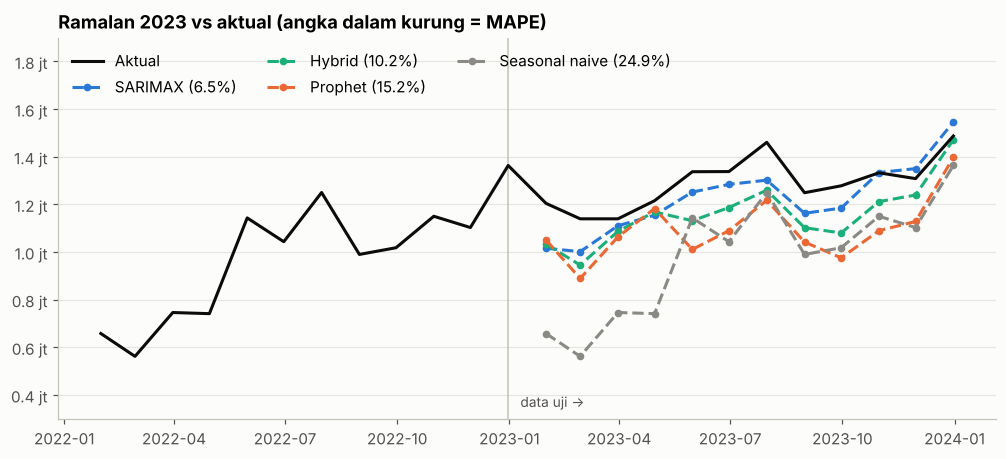

In [4]:
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(y['2022':].index, y['2022':].values, color=COLORS['Aktual'], label='Aktual', zorder=5)
for name in ['SARIMAX', 'Hybrid', 'Prophet', 'Seasonal naive']:
    ax.plot(test.index, preds[name], color=COLORS[name], ls='--', marker='o', ms=4,
            label=f"{name} ({results.loc[name, 'MAPE (%)']:.1f}%)")
ax.axvline(pd.Timestamp('2022-12-31'), color='#c3c2b7', lw=1)
ax.text(pd.Timestamp('2023-01-10'), 0.35e6, 'data uji →', fontsize=9, color='#52514e')
ax.set_ylim(0.3e6, 1.9e6); million_axis(ax)
ax.legend(loc='upper left', ncol=3)
ax.set_title('Ramalan 2023 vs aktual (angka dalam kurung = MAPE)')
fig.savefig('../images/02_ramalan_2023.png')
plt.show()

**Temuan:** SARIMAX adalah model terbaik. Hybrid justru lebih buruk dari SARIMAX sendirian karena Prophet, yang meremehkan hampir semua bulan, ikut menarik ramalannya ke bawah. Semua model mengalahkan baseline seasonal naive, yang gagal karena 2022 masih tahun pemulihan.

## 2. Uji sensitivitas: tanpa Maret 2023

Maret 2023 kemungkinan salah input (nilainya identik dengan Februari).

In [5]:
mask = test.index.month != 3
metrics_table(test[mask], preds.loc[mask].drop(columns='Aktual'))

,MAE,RMSE,MAPE (%)
SARIMAX,"87,839.07","102,221.18",6.86
Hybrid,"138,214.73","152,263.93",10.74
Prophet,"207,016.61","223,281.96",15.94
Seasonal naive,"302,512.55","337,222.65",24.07


Urutan model tidak berubah, jadi kesimpulan tidak bergantung pada data yang meragukan itu.

## 3. Perbandingan dengan versi skripsi

Bagian ini menjalankan ulang konfigurasi persis seperti di skripsi untuk menunjukkan dari mana angka-angka skripsi berasal dan kenapa angkanya lebih bagus.

| | Versi skripsi | Versi ini |
|---|---|---|
| Fitur libur SARIMAX | `is_holiday` (tanggal akhir bulan, hampir selalu 0) | `covid` + `lebaran` |
| Parameter Prophet | dipilih berdasarkan MAPE data uji 2023 | default library, tidak di-tuning |
| Bobot hybrid | dioptimasi pada data uji 2023 | 50/50 tetap |
| Baseline pembanding | tidak ada | seasonal naive |

In [6]:
from prophet import Prophet

h = load_holidays()
is_holiday = lambda idx: pd.DataFrame({'is_holiday': idx.isin(h['tanggal']).astype(int)}, index=idx)

# SARIMAX versi skripsi
r = fit_sarimax(train, (0, 1, 2), (0, 1, 1, 12), is_holiday(train.index))
skripsi_sarimax = r.get_forecast(12, exog=is_holiday(test.index)).predicted_mean.to_numpy()

# Prophet versi skripsi (changepoint_prior_scale=0.5 dipilih berdasarkan skor 2023)
df = pd.DataFrame({'ds': train.index, 'y': train.to_numpy()})
df['Lockdown'] = df['ds'].dt.year.isin([2020, 2021]).astype(int)
m = Prophet(holidays=pd.DataFrame({'ds': h['tanggal'], 'holiday': 'holiday'}),
            seasonality_prior_scale=5.0, holidays_prior_scale=10.0, changepoint_prior_scale=0.5)
m.add_regressor('Lockdown'); m.fit(df)
fut = pd.DataFrame({'ds': test.index, 'Lockdown': 0})
skripsi_prophet = m.predict(fut)['yhat'].to_numpy()

# Bobot hybrid versi skripsi: dicari dengan grid pada MAE data uji
weights = np.round(np.arange(0, 1.01, 0.1), 1)
w_best = min(weights, key=lambda w: metrics(test, w * skripsi_prophet + (1 - w) * skripsi_sarimax)['MAE'])
skripsi_hybrid = w_best * skripsi_prophet + (1 - w_best) * skripsi_sarimax
print('Bobot Prophet terpilih (dari data uji):', w_best)

skripsi = metrics_table(test, {'SARIMAX': skripsi_sarimax, 'Prophet': skripsi_prophet, 'Hybrid': skripsi_hybrid})
skripsi

Bobot Prophet terpilih (dari data uji): 0.5


,MAE,RMSE,MAPE (%)
Hybrid,"56,919.87","70,161.68",4.34
Prophet,"79,182.17","91,862.10",6.06
SARIMAX,"98,680.37","113,323.83",7.72


In [7]:
compare = pd.DataFrame({
    'MAPE skripsi (%)': skripsi['MAPE (%)'],
    'MAPE evaluasi ulang (%)': results['MAPE (%)'],
}).loc[['Hybrid', 'Prophet', 'SARIMAX']]
compare['Peringkat skripsi'] = compare['MAPE skripsi (%)'].rank().astype(int)
compare['Peringkat ulang'] = compare['MAPE evaluasi ulang (%)'].rank().astype(int)
compare

,MAPE skripsi (%),MAPE evaluasi ulang (%),Peringkat skripsi,Peringkat ulang
Hybrid,4.34,10.23,1,2
Prophet,6.06,15.16,2,3
SARIMAX,7.72,6.50,3,1


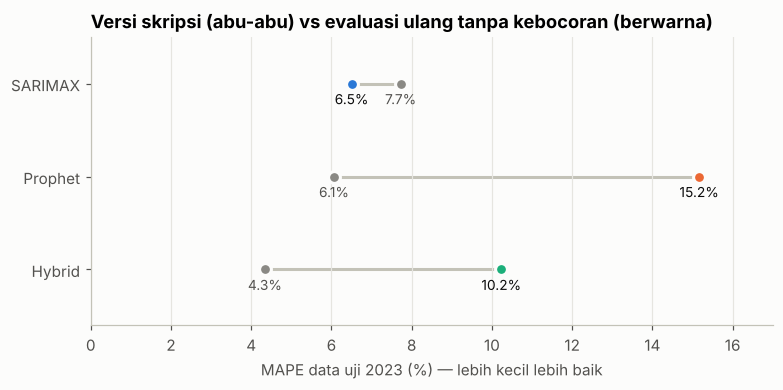

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.4))
models = ['SARIMAX', 'Prophet', 'Hybrid']
ypos = np.arange(len(models))
for i, mname in enumerate(models):
    a, b = compare.loc[mname, 'MAPE skripsi (%)'], compare.loc[mname, 'MAPE evaluasi ulang (%)']
    ax.plot([a, b], [i, i], color='#c3c2b7', lw=2, zorder=1)
    ax.scatter(a, i, s=60, color='#8a8984', zorder=2, edgecolor='#fcfcfb', linewidth=2)
    ax.scatter(b, i, s=60, color=COLORS[mname], zorder=3, edgecolor='#fcfcfb', linewidth=2)
    ax.text(a, i + 0.22, f'{a:.1f}%', ha='center', fontsize=9, color='#52514e')
    ax.text(b, i + 0.22, f'{b:.1f}%', ha='center', fontsize=9, color='#0b0b0b')
ax.set_yticks(ypos, models); ax.set_ylim(-0.5, 2.6); ax.invert_yaxis()
ax.set_xlim(0, 17); ax.set_xlabel('MAPE data uji 2023 (%) — lebih kecil lebih baik')
ax.grid(axis='x', color='#e6e5e0'); ax.grid(axis='y', visible=False)
ax.set_title('Versi skripsi (abu-abu) vs evaluasi ulang tanpa kebocoran (berwarna)')
fig.savefig('../images/03_skripsi_vs_ulang.png')
plt.show()

## 4. Kesimpulan

1. **Dengan evaluasi yang bersih, SARIMAX adalah model terbaik** (MAPE sekitar 6,5%). Kesimpulan skripsi bahwa hybrid paling unggul tidak bertahan.
2. **Angka hybrid 4,34% di skripsi terlalu optimis** karena parameter Prophet dan bobot hybrid sama-sama dipilih dengan melihat data uji.
3. **SARIMAX versi ini lebih baik dari versi skripsi** (6,5% vs 7,7%) setelah fitur libur yang hampir kosong diganti dengan dummy COVID dan Lebaran.
4. **Ketidakpastian tetap besar.** Data uji hanya 12 bulan, 43% data latih adalah hasil interpolasi, dan hanya ada satu tahun normal pasca-COVID. Selisih beberapa persen antar model tidak boleh dibaca sebagai bukti kuat.

In [9]:
preds.to_csv('../data/processed/ramalan_2023_semua_model.csv', index_label='bulan')
compare.to_csv('../data/processed/perbandingan_skripsi_vs_ulang.csv')